# Almaty PM2.5 forecasting with AirData.kz

Train your own models to predict station-level PM2.5 **1, 6 and 24 hours ahead**.
Compare persistence, same-hour-yesterday, Ridge regression and XGBoost using chronological evaluation.

**Google Colab:** select **Runtime → Run all**. A CPU runtime is sufficient. This notebook downloads a pinned dataset version; no API key or Google Drive mount is required.
Outputs are purposeful tables and charts, followed by saved models and an experiment archive.

Default station: **Almaty US Embassy (`oaq_25903`)**. Forecasts describe that station, not every neighborhood.
The default experiment trains before 2023, selects settings on 2023, and evaluates once on 2024.

Source: [AirData.kz repository](https://github.com/qazybekb/AirDatakz-OpenData).
License: CC BY-NC 4.0, with attribution and applicable upstream terms.
Credit: AirData.kz / Global Shapers Almaty Hub and the original measurement providers.


In [ ]:
# Quiet installation of the experiment dependencies. Restart the runtime if Colab requests it.
%pip install -q numpy==2.2.0 pandas==2.2.3 scikit-learn==1.7.2 xgboost==3.1.1 matplotlib==3.10.0 joblib==1.5.2


In [1]:
from pathlib import Path
from urllib.request import urlopen, Request
import hashlib
import importlib.metadata
import json
import platform
import shutil
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, FileLink
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})


## Experiment configuration

Keep the test period untouched while selecting settings. Choose a station from the audit table below, then rerun from here.
For a new station, check that its history covers all three periods.
`QUICK_RUN=True` tries two Ridge and two XGBoost settings per horizon.


In [2]:
DATA_COMMIT = '119cf2c278def3129f14cef9380cced9de1f3161'
DATA_URL = f'https://raw.githubusercontent.com/qazybekb/AirDatakz-OpenData/{DATA_COMMIT}/almaty/pm25.csv.gz'
STATION_ID = 'oaq_25903'
START = pd.Timestamp('2020-04-01', tz='UTC')
TRAIN_END = pd.Timestamp('2023-01-01', tz='UTC')
VALID_END = pd.Timestamp('2024-01-01', tz='UTC')
TEST_END = pd.Timestamp('2025-01-01', tz='UTC')
HORIZONS = (1, 6, 24)
QUICK_RUN = True
SEED = 42
DATA_DIR = Path('data')
OUT_DIR = Path('artifacts')
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
DATA_FILE = DATA_DIR / 'almaty_pm25.csv.gz'
assert START < TRAIN_END < VALID_END < TEST_END


## Download and inspect the dataset

The local cache is checked against its pinned URL. The experiment records its SHA-256 checksum.
The audit includes all sources; early AirKaz records can be daily despite appearing in the hourly file.
WAQI values can be reconstructed from AQI. Avoid treating these sources as interchangeable.


In [3]:
cache_meta = DATA_FILE.with_suffix('.source.json')
cached_url = json.loads(cache_meta.read_text()).get('url') if cache_meta.exists() else None
if not DATA_FILE.exists() or cached_url != DATA_URL:
    request = Request(DATA_URL, headers={'User-Agent': 'AirData-Colab-Research'})
    with urlopen(request, timeout=120) as response:
        payload = response.read()
    temp_file = DATA_FILE.with_suffix('.download')
    temp_file.write_bytes(payload)
    temp_file.replace(DATA_FILE)
    cache_meta.write_text(json.dumps({'url': DATA_URL}), encoding='utf-8')
DATA_SHA256 = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_FILE, compression='gzip', dtype={'station_id': 'string', 'source': 'string'})
required = {'datetime_utc', 'station_id', 'station_name', 'source', 'value_ugm3'}
assert required <= set(raw.columns), f'Missing required columns: {required - set(raw.columns)}'
raw['datetime_utc'] = pd.to_datetime(raw['datetime_utc'], utc=True, errors='coerce')
raw['value_ugm3'] = pd.to_numeric(raw['value_ugm3'], errors='coerce')
source_audit = raw.groupby('source').agg(
    records=('station_id', 'size'), stations=('station_id', 'nunique'),
    first_record=('datetime_utc', 'min'), last_record=('datetime_utc', 'max'))
display(source_audit)


,records,stations,first_record,last_record
source,,,,
airgradient,121236,152,2026-03-17 23:00:00+00:00,2026-10-09 19:00:00+00:00
airkaz,21980,40,2017-03-21 18:00:00+00:00,2020-12-30 18:00:00+00:00
kgmt,350140,11,2020-07-12 05:00:00+00:00,2026-10-09 18:00:00+00:00
openaq,46840,15,2020-04-09 16:00:00+00:00,2026-03-18 21:00:00+00:00
waqi,57349,21,2023-10-29 12:00:00+00:00,2026-10-09 19:00:00+00:00


In [4]:
station_audit = raw.groupby(['station_id', 'station_name', 'source']).agg(
    records=('value_ugm3', 'count'), first_record=('datetime_utc', 'min'),
    last_record=('datetime_utc', 'max')).sort_values('records', ascending=False)
display(station_audit.head(20))


,,,records,first_record,last_record
station_id,station_name,source,,,
kgmt_27,PCP #31,kgmt,43302,2020-07-12 05:00:00+00:00,2026-10-09 18:00:00+00:00
kgmt_28,PCP #30,kgmt,41434,2020-07-12 05:00:00+00:00,2026-10-08 18:00:00+00:00
kgmt_97,PCP #28,kgmt,39923,2020-07-12 05:00:00+00:00,2026-10-09 18:00:00+00:00
kgmt_26,PCP #29,kgmt,38807,2020-07-12 05:00:00+00:00,2026-10-08 18:00:00+00:00
oaq_25903,Almaty (US Embassy),openaq,36071,2020-04-09 16:00:00+00:00,2025-11-14 10:00:00+00:00
kgmt_59,PCP #6,kgmt,34660,2020-07-12 05:00:00+00:00,2026-10-09 18:00:00+00:00
kgmt_57,PCP #4,kgmt,32311,2020-10-31 18:00:00+00:00,2026-04-24 18:00:00+00:00
kgmt_58,PCP #3,kgmt,31229,2020-07-12 05:00:00+00:00,2025-12-22 09:00:00+00:00
kgmt_60,PCP #5,kgmt,28872,2020-07-12 05:00:00+00:00,2025-12-22 09:00:00+00:00


## Clean one station and preserve missing hours

Remove invalid timestamps, nonnumeric or negative concentrations. Preserve high readings: they may be real pollution episodes.
Resolve duplicate station timestamps by averaging and report their count.
Reindex to an exact UTC hourly grid without filling targets or interpolating from the future.
Features later use calendar time in `Asia/Almaty`, including historical timezone offsets.


In [5]:
selected = raw.loc[raw['station_id'].eq(STATION_ID)].copy()
if selected.empty:
    raise ValueError('Station not found. Select an ID from station_audit.')
STATION_NAME = selected['station_name'].mode().iloc[0]
invalid = (selected['datetime_utc'].isna() | selected['value_ugm3'].isna()
           | selected['value_ugm3'].lt(0))
valid = selected.loc[~invalid].copy()
duplicate_rows = int(valid.duplicated('datetime_utc').sum())
series = valid.groupby('datetime_utc')['value_ugm3'].mean().sort_index()
grid = pd.date_range(START, TEST_END, freq='h', inclusive='left', name='datetime_utc')
pm25 = series.reindex(grid).rename('pm25')
assert pm25.index.is_unique and pm25.index.is_monotonic_increasing
display(pd.DataFrame({
    'value': [STATION_NAME, len(selected), int(invalid.sum()), duplicate_rows,
              len(pm25), int(pm25.notna().sum()), round(pm25.notna().mean(), 3)]},
    index=['station', 'input records', 'invalid records', 'duplicate timestamp rows',
           'expected hours in experiment', 'observed hours', 'hourly coverage']))


,value
station,Almaty (US Embassy)
input records,36071
invalid records,0
duplicate timestamp rows,0
expected hours in experiment,41664
observed hours,28507
hourly coverage,0.684


## Exploratory analysis

These descriptive plots include the test period for transparency about coverage, but do not use test errors to tune models.
Daily values below are for this station and require at least 18 observed hours.
Gaps remain visible. The repository reports source changes, timestamp corrections, and a 2026 collection interruption.


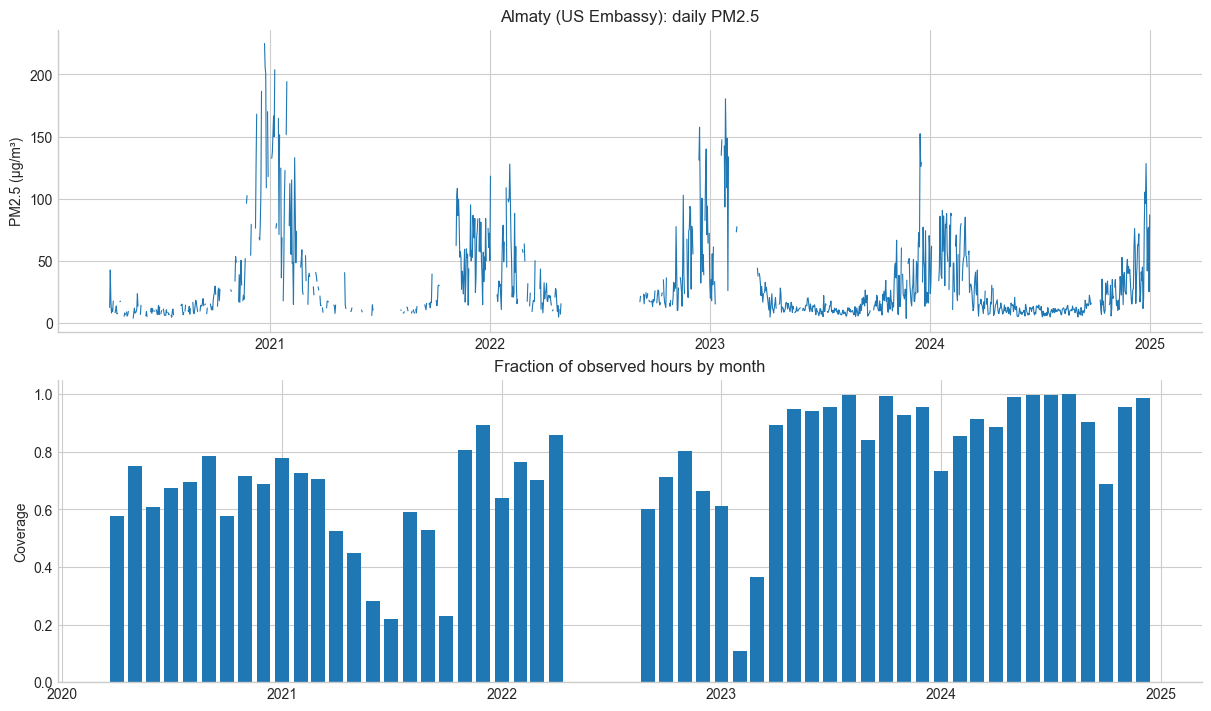

In [6]:
monthly_coverage = pm25.notna().resample('MS').mean()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
daily_station = pm25.resample('D').mean().where(pm25.resample('D').count().ge(18))
axes[0].plot(daily_station.index, daily_station, linewidth=0.8)
axes[0].set(title=f'{STATION_NAME}: daily PM2.5', ylabel='PM2.5 (µg/m³)')
axes[1].bar(monthly_coverage.index, monthly_coverage, width=23)
axes[1].set(title='Fraction of observed hours by month', ylabel='Coverage', ylim=(0, 1.05))
plt.show()


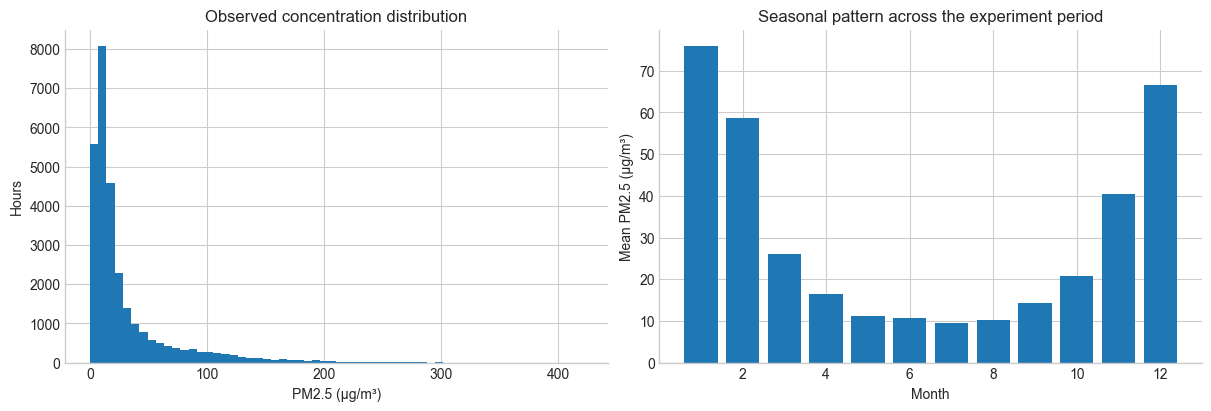

In [7]:
local_frame = pm25.to_frame()
local_frame['month'] = local_frame.index.tz_convert('Asia/Almaty').month
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(pm25.dropna(), bins=60)
axes[0].set(title='Observed concentration distribution', xlabel='PM2.5 (µg/m³)', ylabel='Hours')
month_means = local_frame.groupby('month')['pm25'].mean()
axes[1].bar(month_means.index, month_means)
axes[1].set(title='Seasonal pattern across the experiment period', xlabel='Month', ylabel='Mean PM2.5 (µg/m³)')
plt.show()


## Build forecasting features

A forecast origin is the end of the measured hour indexed by `t`; its PM2.5 reading must already be available.
The label is the reading at exactly `t + horizon` hours. This is concentration at that hour, not the average over the next day.
Reporting delays are not recorded here, so operational deployment would need an additional delay buffer.

Use the current observation, exact-hour lags and trailing averages/counts. All windows end at `t`.
The historical-only feature set supports an ablation against history plus calendar features.
Missing inputs are imputed using training data. Missing labels are excluded.


In [8]:
def make_features(series):
    features = pd.DataFrame({'pm25_now': series})
    for lag in (1, 2, 3, 6, 12, 24, 48, 72, 168):
        features[f'pm25_lag_{lag}h'] = series.shift(lag)
    for window in (6, 24, 72, 168):
        roll = series.rolling(window, min_periods=max(2, window // 4))
        features[f'mean_{window}h'] = roll.mean()
        features[f'std_{window}h'] = roll.std()
        features[f'observed_{window}h'] = series.rolling(window, min_periods=1).count()
    local_time = series.index.tz_convert('Asia/Almaty')
    for name, values, period in (
        ('hour', local_time.hour, 24), ('weekday', local_time.dayofweek, 7),
        ('year_day', local_time.dayofyear - 1, 365.25)):
        features[f'{name}_sin'] = np.sin(2 * np.pi * values / period)
        features[f'{name}_cos'] = np.cos(2 * np.pi * values / period)
    return features.astype('float32')

features = make_features(pm25)
history_features = [c for c in features if not c.endswith(('_sin', '_cos'))]
all_features = features.columns.tolist()
eligible = pm25.notna() & features['observed_24h'].ge(18) & features['pm25_lag_168h'].notna()

def horizon_data(horizon):
    frame = features.copy()
    frame['target'] = pm25.shift(-horizon)
    frame['target_time'] = frame.index + pd.Timedelta(hours=horizon)
    # A seasonal baseline refers to the same clock hour one day before the target.
    frame['seasonal_baseline'] = pm25.shift(24 - horizon)
    frame = frame.loc[eligible & frame['target'].notna() & frame['seasonal_baseline'].notna()]
    return frame

datasets = {h: horizon_data(h) for h in HORIZONS}


## Chronological splits with a boundary gap

Split by both forecast-origin time and target time. Training labels cannot enter validation; validation labels cannot enter test.
No random split, and no cross-station row shifts. All models and baselines use identical eligible rows per horizon.
The test mimics repeated forecasts: past observations arriving during the test period can be used for later forecasts without retraining.


In [9]:
def split_data(frame):
    train = frame.loc[(frame.index < TRAIN_END) & frame['target_time'].lt(TRAIN_END)]
    valid = frame.loc[(frame.index >= TRAIN_END) & (frame.index < VALID_END)
                      & frame['target_time'].lt(VALID_END)]
    test = frame.loc[(frame.index >= VALID_END) & (frame.index < TEST_END)
                     & frame['target_time'].lt(TEST_END)]
    if min(map(len, (train, valid, test))) < 200:
        raise ValueError('Insufficient observations in a split. Review station coverage and experiment dates.')
    assert train['target_time'].max() < valid.index.min()
    assert valid['target_time'].max() < test.index.min()
    return {'train': train, 'validation': valid, 'test': test}

splits = {h: split_data(frame) for h, frame in datasets.items()}
display(pd.DataFrame([
    {'horizon_hours': h, 'split': name, 'rows': len(part),
     'first_origin': part.index.min(), 'last_origin': part.index.max(),
     'last_target': part['target_time'].max()}
    for h, parts in splits.items() for name, part in parts.items()
]))


,horizon_hours,split,rows,first_origin,last_origin,last_target
0,1,train,6025,2020-04-16 16:00:00+00:00,2022-12-31 22:00:00+00:00,2022-12-31 23:00:00+00:00
1,1,validation,5792,2023-01-01 00:00:00+00:00,2023-12-31 22:00:00+00:00,2023-12-31 23:00:00+00:00
2,1,test,6924,2024-01-01 00:00:00+00:00,2024-12-31 22:00:00+00:00,2024-12-31 23:00:00+00:00
3,6,train,5903,2020-04-16 16:00:00+00:00,2022-12-31 17:00:00+00:00,2022-12-31 23:00:00+00:00
4,6,validation,5775,2023-01-01 00:00:00+00:00,2023-12-31 17:00:00+00:00,2023-12-31 23:00:00+00:00
5,6,test,6883,2024-01-01 00:00:00+00:00,2024-12-31 17:00:00+00:00,2024-12-31 23:00:00+00:00
6,24,train,5430,2020-04-17 09:00:00+00:00,2022-12-28 17:00:00+00:00,2022-12-29 17:00:00+00:00
7,24,validation,5594,2023-01-01 00:00:00+00:00,2023-12-30 23:00:00+00:00,2023-12-31 23:00:00+00:00
8,24,test,6683,2024-01-01 00:00:00+00:00,2024-12-30 23:00:00+00:00,2024-12-31 23:00:00+00:00


## Train and select models on validation only

Compare two baseline forecasts and two learned model families. Select each family's settings using validation MAE.
XGBoost uses CPU histogram training and four threads. Training times below are measured on your runtime.
Run more candidates with `QUICK_RUN=False`; this multiplies the number of fits.


In [ ]:
import json
import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

def metrics(y, prediction):
    return {'MAE': mean_absolute_error(y, prediction),
            'RMSE': root_mean_squared_error(y, prediction),
            'R2': r2_score(y, prediction)}

def build_model(family, settings):
    steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if family == 'Ridge':
        steps += [('scale', StandardScaler()), ('model', Ridge(alpha=settings['alpha']))]
    else:
        steps += [('model', XGBRegressor(
            objective='reg:squarederror', tree_method='hist', n_jobs=4,
            random_state=SEED, verbosity=0, subsample=0.85, colsample_bytree=0.9,
            **settings))]
    return Pipeline(steps)

ridge_candidates = [{'alpha': alpha} for alpha in ([1.0, 100.0] if QUICK_RUN else [0.1, 1.0, 10.0, 100.0])]
xgb_candidates = [
    {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 10.0},
    {'n_estimators': 350, 'max_depth': 5, 'learning_rate': 0.04, 'reg_lambda': 10.0},
]
if not QUICK_RUN:
    xgb_candidates += [
        {'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.03, 'reg_lambda': 20.0},
        {'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.03, 'reg_lambda': 20.0},
    ]

validation_rows, selected_models, ablation_rows = [], {}, []
for horizon, parts in splits.items():
    train, valid = parts['train'], parts['validation']
    for name, prediction in [('Persistence', valid['pm25_now']),
                             ('Same hour yesterday', valid['seasonal_baseline'])]:
        validation_rows.append({'horizon_hours': horizon, 'model': name, 'settings': '{}',
                                'fit_seconds': 0.0, **metrics(valid['target'], prediction)})
    for family, candidates in [('Ridge', ridge_candidates), ('XGBoost', xgb_candidates)]:
        best_mae = np.inf
        for settings in candidates:
            model = build_model(family, settings)
            started = time.perf_counter()
            model.fit(train[all_features], train['target'])
            duration = time.perf_counter() - started
            prediction = np.maximum(model.predict(valid[all_features]), 0)
            scores = metrics(valid['target'], prediction)
            validation_rows.append({'horizon_hours': horizon, 'model': family,
                                    'settings': json.dumps(settings), 'fit_seconds': duration, **scores})
            if scores['MAE'] < best_mae:
                best_mae = scores['MAE']
                selected_models[(horizon, family)] = {'model': model, 'settings': settings.copy()}
        if family == 'XGBoost':
            history_model = build_model(family, selected_models[(horizon, family)]['settings'])
            history_model.fit(train[history_features], train['target'])
            historical_prediction = np.maximum(history_model.predict(valid[history_features]), 0)
            ablation_rows += [
                {'horizon_hours': horizon, 'features': 'Pollution history',
                 **metrics(valid['target'], historical_prediction)},
                {'horizon_hours': horizon, 'features': 'Pollution history + calendar',
                 'MAE': best_mae,
                 **{k: v for k, v in metrics(valid['target'], np.maximum(
                     selected_models[(horizon, family)]['model'].predict(valid[all_features]), 0)).items() if k != 'MAE'}}
            ]
validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(3))
display(pd.DataFrame(ablation_rows).round(3))


## Lock settings and evaluate the held-out year

Select the preferred learned model using validation only, then refit each selected family on all available pre-test examples.
Evaluate all comparisons on 2024. Nonnegative clipping is fixed in advance for both learned models.
An improvement is not guaranteed; report honestly if a baseline wins.
Do not adjust settings after inspecting test performance.


In [11]:
preferred_families = {}
for h in HORIZONS:
    best_by_family = validation_results.loc[
        validation_results['horizon_hours'].eq(h) & validation_results['model'].isin(['Ridge', 'XGBoost'])
    ].groupby('model')['MAE'].min()
    preferred_families[h] = best_by_family.idxmin()

test_rows, prediction_frames, final_models = [], [], {}
for horizon, parts in splits.items():
    pretest = datasets[horizon].loc[
        (datasets[horizon].index < VALID_END) & datasets[horizon]['target_time'].lt(VALID_END)]
    test = parts['test']
    predictions = {'Persistence': test['pm25_now'].to_numpy(),
                   'Same hour yesterday': test['seasonal_baseline'].to_numpy()}
    for family in ('Ridge', 'XGBoost'):
        model = build_model(family, selected_models[(horizon, family)]['settings'])
        started = time.perf_counter()
        model.fit(pretest[all_features], pretest['target'])
        fit_seconds = time.perf_counter() - started
        infer_started = time.perf_counter()
        predictions[family] = np.maximum(model.predict(test[all_features]), 0)
        infer_seconds = time.perf_counter() - infer_started
        final_models[(horizon, family)] = model
        test_rows.append({'horizon_hours': horizon, 'model': family,
                          'fit_seconds': fit_seconds, 'predict_seconds': infer_seconds,
                          **metrics(test['target'], predictions[family])})
    for name in ('Persistence', 'Same hour yesterday'):
        test_rows.append({'horizon_hours': horizon, 'model': name, 'fit_seconds': 0,
                          'predict_seconds': 0, **metrics(test['target'], predictions[name])})
    for name, prediction in predictions.items():
        prediction_frames.append(pd.DataFrame({
            'origin_time': test.index, 'target_time': test['target_time'].to_numpy(),
            'horizon_hours': horizon, 'model': name,
            'actual': test['target'].to_numpy(), 'prediction': prediction}))

test_results = pd.DataFrame(test_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
persistence_mae = test_results.loc[test_results['model'].eq('Persistence')].set_index('horizon_hours')['MAE']
test_results['MAE_improvement_vs_persistence_pct'] = 100 * (
    1 - test_results['MAE'] / test_results['horizon_hours'].map(persistence_mae).replace(0, np.nan))
display(test_results.sort_values(['horizon_hours', 'MAE']).round(3))


,horizon_hours,model,fit_seconds,predict_seconds,MAE,RMSE,R2,MAE_improvement_vs_persistence_pct
1,1,XGBoost,0.646,0.023,5.395,10.321,0.874,1.896
0,1,Ridge,0.039,0.007,5.494,10.267,0.875,0.108
2,1,Persistence,0.000,0.000,5.500,10.835,0.861,0.000
3,1,Same hour yesterday,0.000,0.000,13.697,24.664,0.279,-149.061
5,6,XGBoost,0.260,0.013,11.011,19.747,0.540,22.164
4,6,Ridge,0.038,0.006,11.800,20.089,0.524,16.583
7,6,Same hour yesterday,0.000,0.000,13.737,24.870,0.270,2.890
6,6,Persistence,0.000,0.000,14.146,27.185,0.128,0.000
9,24,XGBoost,0.288,0.014,12.161,21.184,0.470,9.585
8,24,Ridge,0.031,0.006,12.316,20.747,0.492,8.433


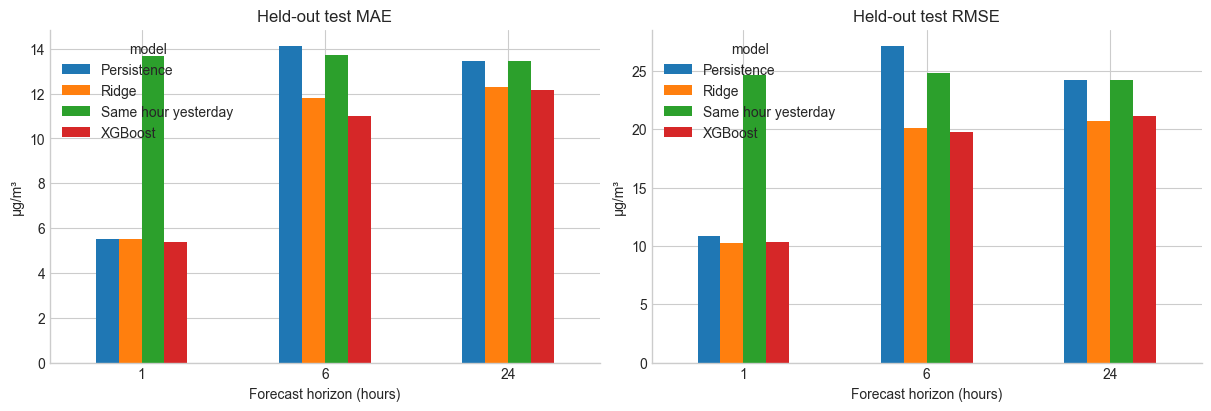

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for metric, ax in zip(('MAE', 'RMSE'), axes):
    test_results.pivot(index='horizon_hours', columns='model', values=metric).plot.bar(ax=ax)
    ax.set(title=f'Held-out test {metric}', xlabel='Forecast horizon (hours)', ylabel='µg/m³')
    ax.tick_params(axis='x', rotation=0)
plt.show()


## Analyze errors and difficult periods

Report errors by season and by concentration. The high-pollution group uses the 90th percentile of pre-test observations,
not a health threshold. Inspect the largest misses rather than relying only on an overall average.


In [13]:
error_frame = predictions.copy()
error_frame['abs_error'] = (error_frame['actual'] - error_frame['prediction']).abs()
error_frame['squared_error'] = (error_frame['actual'] - error_frame['prediction']) ** 2
target_month = pd.to_datetime(error_frame['target_time'], utc=True).dt.tz_convert('Asia/Almaty').dt.month
error_frame['season'] = target_month.map({12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',
                                        6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'})
peak_cutoff = pm25.loc[pm25.index < VALID_END].quantile(0.9)
error_frame['concentration_group'] = np.where(error_frame['actual'] >= peak_cutoff,
                                             'High: pre-test 90th percentile or above', 'Below pre-test 90th percentile')
season_errors = error_frame.groupby(['horizon_hours', 'model', 'season']).agg(
    n=('abs_error','size'), MAE=('abs_error','mean'), MSE=('squared_error','mean')).reset_index()
season_errors['RMSE'] = np.sqrt(season_errors.pop('MSE'))
peak_errors = error_frame.groupby(['horizon_hours','model','concentration_group']).agg(
    n=('abs_error','size'), MAE=('abs_error','mean')).reset_index()
display(season_errors.round(3))
display(peak_errors.round(3))
preferred_errors = error_frame.loc[
    error_frame['model'].eq(error_frame['horizon_hours'].map(preferred_families))]
display(preferred_errors.nlargest(10, 'abs_error')[
    ['origin_time','target_time','horizon_hours','model','actual','prediction','abs_error']].round(2))


,horizon_hours,model,season,n,MAE,RMSE
0,1,Persistence,Autumn,1531,4.988,8.467
1,1,Persistence,Spring,1727,4.089,6.460
2,1,Persistence,Summer,2198,2.624,3.943
3,1,Persistence,Winter,1468,11.998,20.165
4,1,Ridge,Autumn,1531,4.916,8.018
5,1,Ridge,Spring,1727,4.134,6.194
6,1,Ridge,Summer,2198,2.766,3.943
7,1,Ridge,Winter,1468,11.779,19.018
8,1,Same hour yesterday,Autumn,1531,12.243,18.348
9,1,Same hour yesterday,Spring,1727,9.591,14.287


,horizon_hours,model,concentration_group,n,MAE
0,1,Persistence,Below pre-test 90th percentile,6548,4.780
1,1,Persistence,High: pre-test 90th percentile or above,376,18.029
2,1,Ridge,Below pre-test 90th percentile,6548,4.728
3,1,Ridge,High: pre-test 90th percentile or above,376,18.819
4,1,Same hour yesterday,Below pre-test 90th percentile,6548,11.749
5,1,Same hour yesterday,High: pre-test 90th percentile or above,376,47.620
6,1,XGBoost,Below pre-test 90th percentile,6548,4.603
7,1,XGBoost,High: pre-test 90th percentile or above,376,19.195
8,6,Persistence,Below pre-test 90th percentile,6513,11.711
9,6,Persistence,High: pre-test 90th percentile or above,370,57.016


,origin_time,target_time,horizon_hours,model,actual,prediction,abs_error
55225,2024-12-31 15:00:00+00:00,2024-12-31 21:00:00+00:00,6,XGBoost,301.0,13.42,287.58
81957,2024-12-30 21:00:00+00:00,2024-12-31 21:00:00+00:00,24,XGBoost,301.0,26.08,274.92
55226,2024-12-31 16:00:00+00:00,2024-12-31 22:00:00+00:00,6,XGBoost,212.0,19.54,192.46
81958,2024-12-30 22:00:00+00:00,2024-12-31 22:00:00+00:00,24,XGBoost,212.0,22.01,189.99
48476,2024-01-24 01:00:00+00:00,2024-01-24 07:00:00+00:00,6,XGBoost,247.0,73.00,174.00
81959,2024-12-30 23:00:00+00:00,2024-12-31 23:00:00+00:00,24,XGBoost,184.0,17.13,166.87
75373,2024-01-23 07:00:00+00:00,2024-01-24 07:00:00+00:00,24,XGBoost,247.0,85.09,161.91
55227,2024-12-31 17:00:00+00:00,2024-12-31 23:00:00+00:00,6,XGBoost,184.0,28.58,155.42
75635,2024-02-05 13:00:00+00:00,2024-02-06 13:00:00+00:00,24,XGBoost,194.0,49.27,144.73
75634,2024-02-05 12:00:00+00:00,2024-02-06 12:00:00+00:00,24,XGBoost,201.0,56.40,144.60


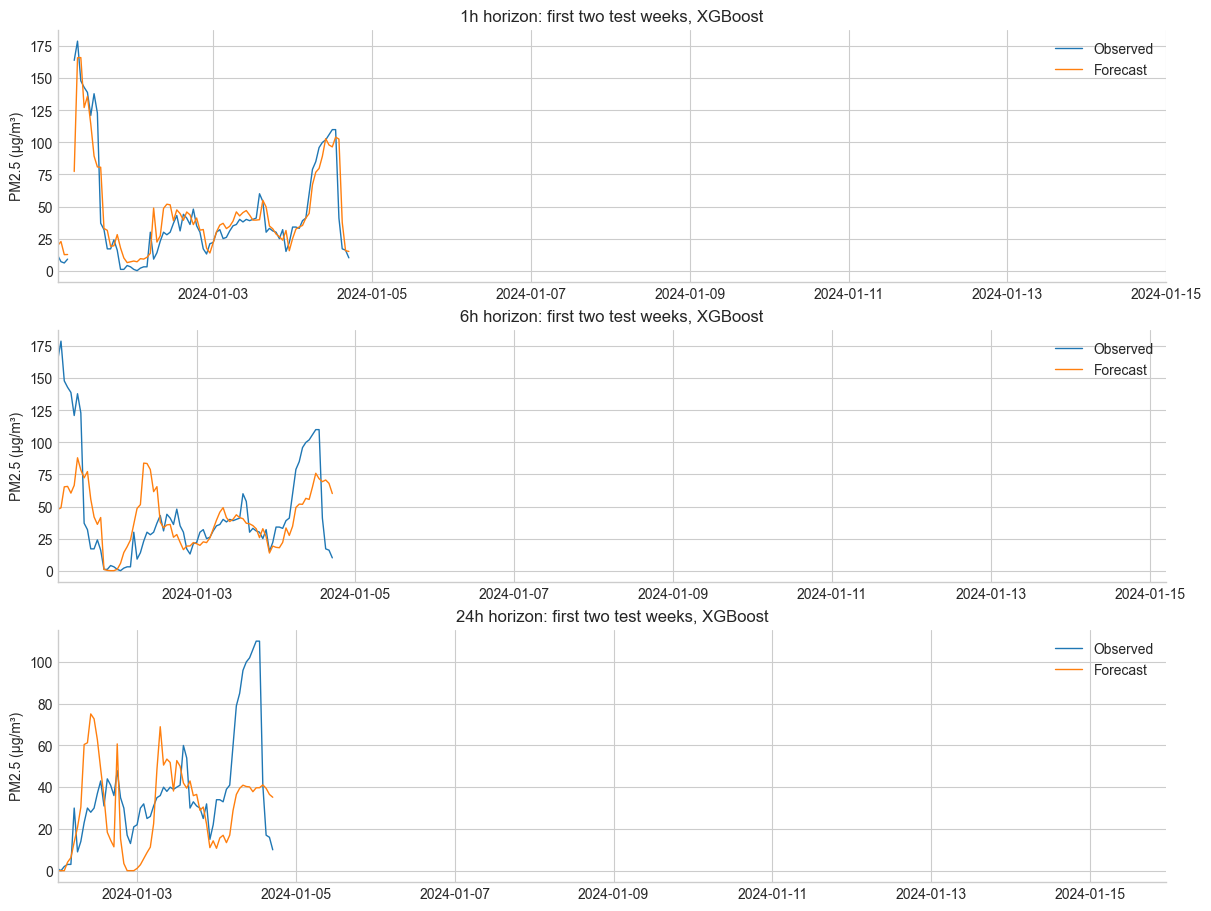

In [14]:
fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(12, 3 * len(HORIZONS)), constrained_layout=True)
for horizon, ax in zip(HORIZONS, np.atleast_1d(axes)):
    example = predictions.loc[predictions['horizon_hours'].eq(horizon)
                              & predictions['model'].eq(preferred_families[horizon])].sort_values('target_time')
    window_start = example['target_time'].iloc[0]
    example = example.loc[example['target_time'] < window_start + pd.Timedelta(days=14)]
    plot_grid = pd.date_range(window_start, window_start + pd.Timedelta(days=14), freq='h', inclusive='left')
    example = example.set_index('target_time').reindex(plot_grid)
    ax.plot(example.index, example['actual'], label='Observed', linewidth=1)
    ax.plot(example.index, example['prediction'], label='Forecast', linewidth=1)
    ax.set_xlim(plot_grid[0], plot_grid[-1])
    ax.set(title=f'{horizon}h horizon: first two test weeks, {preferred_families[horizon]}', ylabel='PM2.5 (µg/m³)')
    ax.legend()
plt.show()


## Forecast from a selected historical hour

This demonstration runs the saved-in-memory models on real inputs; it is historical replay, not a live forecast service.
The default selects the first common eligible test origin. You may enter another UTC timestamp.


In [15]:
common_origins = splits[HORIZONS[0]]['test'].index
for h in HORIZONS[1:]:
    common_origins = common_origins.intersection(splits[h]['test'].index)
if common_origins.empty:
    raise ValueError('No common test origins across the configured horizons.')
FORECAST_ORIGIN = common_origins[0]  # Example override: pd.Timestamp('2024-01-15 12:00', tz='UTC')
if FORECAST_ORIGIN not in common_origins:
    raise ValueError('Choose an eligible test origin from common_origins.')
replay = []
for h in HORIZONS:
    family = preferred_families[h]
    estimate = max(float(final_models[(h, family)].predict(features.loc[[FORECAST_ORIGIN], all_features])[0]), 0)
    replay.append({'horizon_hours': h, 'model': family,
                   'target_time_UTC': FORECAST_ORIGIN + pd.Timedelta(hours=h),
                   'forecast_ugm3': estimate,
                   'observed_ugm3': pm25.loc[FORECAST_ORIGIN + pd.Timedelta(hours=h)]})
display(pd.DataFrame(replay).round(2))


,horizon_hours,model,target_time_UTC,forecast_ugm3,observed_ugm3
0,1,XGBoost,2024-01-01 01:00:00+00:00,19.51,12.0
1,6,XGBoost,2024-01-01 06:00:00+00:00,47.70,164.0
2,24,XGBoost,2024-01-02 00:00:00+00:00,0.00,1.0


## Save reproducible outputs

The archive contains fitted pipelines, feature definitions, training settings, dataset version and checksum,
validation and test results, test predictions, error tables and package versions.
Models are refitted only on pre-test data; the year 2024 remains held out.
Only load joblib files that you trust.


In [16]:
validation_results.to_csv(OUT_DIR / 'validation_metrics.csv', index=False)
pd.DataFrame(ablation_rows).to_csv(OUT_DIR / 'validation_feature_ablation.csv', index=False)
test_results.to_csv(OUT_DIR / 'test_metrics.csv', index=False)
predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False)
station_audit.to_csv(OUT_DIR / 'station_audit.csv')
season_errors.to_csv(OUT_DIR / 'season_errors.csv', index=False)
peak_errors.to_csv(OUT_DIR / 'peak_errors.csv', index=False)
for (h, family), model in final_models.items():
    joblib.dump({'pipeline': model, 'features': all_features, 'station_id': STATION_ID,
                 'horizon_hours': h, 'clip_min': 0, 'origin_convention': 'end of measured hour'},
                OUT_DIR / f'{family.lower()}_{h}h.joblib')
manifest = {
    'station_id': STATION_ID, 'station_name': STATION_NAME,
    'dataset_url': DATA_URL, 'dataset_commit': DATA_COMMIT, 'dataset_sha256': DATA_SHA256,
    'periods': {'start': str(START), 'train_end': str(TRAIN_END),
                'validation_end': str(VALID_END), 'test_end': str(TEST_END)},
    'horizons_hours': HORIZONS, 'features': all_features, 'random_seed': SEED,
    'quick_run': QUICK_RUN, 'preferred_families_from_validation': preferred_families,
    'selected_settings': {f'{h}h_{family}': info['settings']
                          for (h, family), info in selected_models.items()},
    'eligibility': 'current observed, >=18 observations in trailing 24h, lag168h and seasonal baseline observed',
    'peak_error_cutoff_ugm3': float(peak_cutoff),
    'python': platform.python_version(),
    'packages': {p: importlib.metadata.version(p)
                 for p in ['numpy','pandas','scikit-learn','xgboost','matplotlib','joblib']},
    'attribution': 'AirData.kz / Global Shapers Almaty Hub; original measurement providers',
    'license': 'CC BY-NC 4.0 and applicable upstream terms',
}
(OUT_DIR / 'experiment.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
(OUT_DIR / 'README.txt').write_text(
    'Almaty station PM2.5 forecasts at 1, 6 and 24 hours.\n'
    'Models use past PM2.5 and calendar features.\n'
    'Settings selected on validation; 2024 used only for final testing.\n'
    'Inference: build features as in the notebook, preserve column order, predict with pipeline, clip at zero.\n'
    'See experiment.json for provenance, environment and eligibility.\n'
    'Credit AirData.kz and original providers. CC BY-NC 4.0; upstream terms apply.\n', encoding='utf-8')
archive_path = shutil.make_archive('almaty_pm25_experiment', 'zip', root_dir=OUT_DIR)
display(FileLink(archive_path))


### Download the experiment archive in Colab

Run the following optional cell to save the ZIP to your computer.


In [17]:
try:
    from google.colab import files
except ImportError:
    display(FileLink(archive_path))
else:
    files.download(archive_path)


## Interpretation and limitations

- Report test MAE and RMSE separately for each horizon; compare with both baselines.
- Use measured training times rather than estimates. Report the calendar-feature ablation and largest errors.
- Eligible rows exclude gaps and some incomplete histories. Scores describe this subset, not every hour.
- A single station does not establish accuracy across Almaty. Other stations and sources need separate evaluation.
- The published dataset has retrospective quality filtering; performance on raw live feeds may differ.
- No weather is used in this initial experiment. A next experiment can add weather available at forecast time,
  using archived forecasts when predicting future weather-dependent pollution; retrospective reanalysis alone does not simulate operational availability.
- These concentration forecasts are not medical advice or a validated public alert system.
- A useful extension is validation-based uncertainty intervals; avoid presenting point forecasts as certain.

**For the defense:** explain the forecast origin, chronological boundary gap, missing-hour handling,
baseline definitions, validation selection, held-out test results and station/source limitations.
